# GW for Multi-omics

A [variety of single-cell measurements](https://en.wikipedia.org/wiki/Single-cell_analysis) can provide cell characteristics that can be combined, to understand biological mechanisms. These measurements can describe [epigenetic changes](https://en.wikipedia.org/wiki/Single_cell_epigenomics) (DNA methylation, chromatin accessibility, histone modifications, chromosome conformation, ...), the genome itself, or track proteins present in the cell ([single-cell sequencing](https://en.wikipedia.org/wiki/Single_cell_sequencing). Because those measurements are usually destructive, one has typically access to no or very few paired samples,
which raises the major challenge of establishing an alignment across two (or more) heterogeneous measurement spaces.

The Gromov-Wasserstein optimal transport framework, implemented in `OTT`, is a useful tool to carry out that cell alignment without aligned pairs.
This approach was proposed by {cite}`demetci:22`, who called it [SCOT](https://github.com/rsinghlab/SCOT), from which this notebook is adapted.

The original `SCOT` code uses [Python Optimal Transport (POT)](https://pythonot.github.io/). We propose a slight modification of the `SCOT` code to use the {class}`~ott.solvers.quadratic.gromov_wasserstein.GromovWasserstein` solver, rather than the `POT` implementation of {func}`~ot.gromov.entropic_gromov_wasserstein` on GPU (see [](#alignment-and-evaluation)). We then use this `OTT` version of the `SCOT` algorithm to perform cell alignment for the SNARE-seq dataset {cite}`chen:19`, which contains two measurements:

 - Chromatin accessibility ([scATAC-seq data](https://en.wikipedia.org/wiki/ATAC-seq))
 - Gene expression ([scRNA-seq data](https://en.wikipedia.org/wiki/Single_cell_sequencing#scRNA-Seq))

## Imports and dataset loading

We clone the `SCOT` repository within the folder that contains this notebook. For later access to data present in the cloned repository, only relative paths are used.

In [1]:
import time

from SCOT.src import evals
from SCOT.src.scotv1 import SCOT

import jax
import numpy as np
import pandas as pd

# import relevant modules from POT
from ot.gromov import gwloss, init_matrix
from sklearn.decomposition import PCA

import matplotlib.pyplot as plt
import seaborn as sns
from IPython import display
from matplotlib import animation

from ott.geometry import geometry
from ott.problems.quadratic import quadratic_problem
from ott.solvers.linear import sinkhorn
from ott.solvers.quadratic import gromov_wasserstein

In [2]:
X = np.load("SCOT/data/SNARE/SNAREseq_atac_feat.npy")
y = np.load("SCOT/data/SNARE/SNAREseq_rna_feat.npy")
X.shape, y.shape

((1047, 19), (1047, 10))

## Using the {class}`~ott.solvers.quadratic.gromov_wasserstein.GromovWasserstein` solver

The following `OTTSCOT` class inherits from the `SCOT` class but overrides the `find_correspondences` method in order to use `OTT` instead of `POT`. The matrix `T` is the optimal transport matrix, coupling points in $x$ to $y$.

In [3]:
class OTTSCOT(SCOT):
    def find_correspondences(self, e: float, verbose: bool = True) -> None:
        geom_xx = geometry.Geometry(self.Cx)
        geom_yy = geometry.Geometry(self.Cy)
        prob = quadratic_problem.QuadraticProblem(
            geom_xx, geom_yy, a=self.p, b=self.q
        )

        linear_solver = sinkhorn.Sinkhorn()
        solver = jax.jit(
            gromov_wasserstein.GromovWasserstein(
                linear_solver,
                epsilon=e,
                max_iterations=1000,
            )
        )

        T = solver(prob).matrix

        constC, hC1, hC2 = init_matrix(
            self.Cx, self.Cy, self.p, self.q, loss_fun="square_loss"
        )
        self.gwdist = gwloss(constC, hC1, hC2, np.array(T))
        self.coupling = T

        if (
            np.isnan(self.coupling).any()
            or np.any(~self.coupling.any(axis=1))
            or np.any(~self.coupling.any(axis=0))
            or sum(sum(self.coupling)) < 0.95
        ):
            self.flag = False
        else:
            self.flag = True

In the `OTTSCOT.align` method, we have two hyperparameters to tune:

- $\varepsilon$, which controls entropy in the regularized optimization problems solved at each inner iteration,
- $k$, to parameterize the nearest neighbors graph used to define closeness between points from the same domain,

The `SCOT` class implements an unsupervised hyperparameter search method which for our `OTTSCOT` outputs returns values of $\varepsilon = 10^{-3}$ and $k=40$.

In [4]:
k = 40
epsilon = 1e-3

The {mod}`pot` and {mod}`ott` cannot be easily compared, because their convergence thresholds target different quantities: while {mod}`pot`'s GW implementation tracks the 2-norm between two successive _optimization variables_ (here, the coupling), and stops when such a norm goes below `tol`), `ott` tracks the difference in the _objective_ values.

## Alignment and evaluation

We now perform the alignment for our dataset.

In [5]:
ottscot = OTTSCOT(X, y)


def marginal_dev(coupling, n, m) -> float:
    out = np.sum(np.abs(np.sum(coupling, axis=0) - 1.0 / n))
    out += np.sum(np.abs(np.sum(coupling, axis=1) - 1.0 / m))
    return out


start = time.time()
X_shifted, y_shifted = ottscot.align(
    k=k, e=epsilon, normalize=True, norm="l2", verbose=False
)  # OTT
end = time.time()

print(
    "Execution time: ",
    round(end - start, 2),
    "s.",
    " Loss:",
    ottscot.gwdist,
    " Marginal deviation : ",
    marginal_dev(ottscot.coupling, X.shape[0], y.shape[0]),
)

Execution time:  8.08 s.  Loss: 0.01660359549252638  Marginal deviation :  0.000995827


For comparison purposes, we also evaluate the original `SCOT` algorithm using `POT`:

In [6]:
potscot = SCOT(X, y)

start = time.time()
X_shifted_pot, y_shifted_pot = potscot.align(
    k=k, e=epsilon, normalize=True, verbose=False
)  # POT
end = time.time()

print(
    "Execution time: ",
    round(end - start, 2),
    "s.",
    " Loss:",
    potscot.gwdist,
    " Marginal deviation : ",
    marginal_dev(potscot.coupling, X.shape[0], y.shape[0]),
)

python3.14/site-packages/ot/bregman/_sinkhorn.py:666: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


Execution time:  22.79 s.  Loss: 0.01651997512848012  Marginal deviation :  0.0013310870921930478


Note that the dataset provides a ground-truth alignment, since we have the identity of each cell for the two domains. This information is used in `SCOT` to define a performance metric for alignments, the fraction of samples closer than the true match (FOSCTTM).

We provide the Average FOSCTTM to align `X` (chromatin accessibility domain) to `Y` (gene expression domain) for each implementation:

In [7]:
fractions = evals.calc_domainAveraged_FOSCTTM(X_shifted, y_shifted)  # OTT
print("OTT FOSCTTM: ", np.mean(fractions).round(4))

OTT FOSCTTM:  0.2256


In [8]:
fractions_pot = evals.calc_domainAveraged_FOSCTTM(X_shifted_pot, y_shifted_pot)
print("POT FOSCTTM: ", np.mean(fractions_pot).round(4))

POT FOSCTTM:  0.2248


FOSCTTM are very close using either backend.

## Visualization

We start with PCA for both domains:

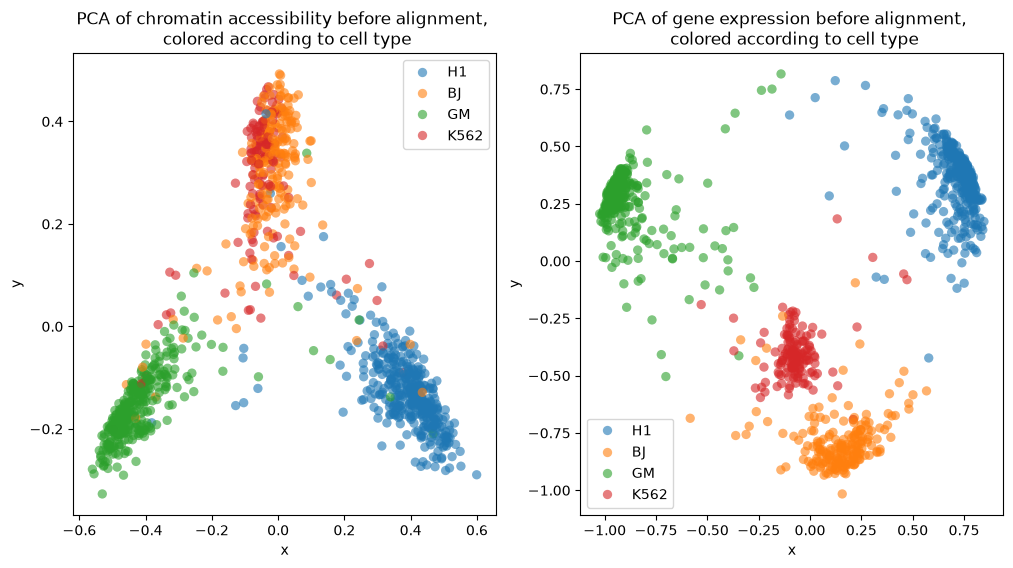

In [9]:
cellTypes_atac = np.loadtxt("SCOT/data/SNARE/SNAREseq_atac_types.txt")
cellTypes_rna = np.loadtxt("SCOT/data/SNARE/SNAREseq_rna_types.txt")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

pca = PCA(n_components=2)
X_pca = pca.fit_transform(ottscot.X)

cell_types = list(set(cellTypes_atac))
cell_types_names = ["H1", "GM", "BJ", "K562"]
colors = ["blue", "purple", "red", "green"]

df1 = pd.DataFrame(
    {
        "x": np.flip(X_pca[:, 0]),
        "y": np.flip(X_pca[:, 1]),
        "cellTypes": np.flip(
            [cell_types_names[int(type) - 1] for type in cellTypes_atac]
        ),
    }
)

sns.scatterplot(
    data=df1,
    x="x",
    y="y",
    hue="cellTypes",
    s=45,
    alpha=0.6,
    edgecolors="none",
    ax=ax1,
)
ax1.legend()
ax1.set_title(
    "PCA of chromatin accessibility before alignment, \n colored according to cell type"
)

pca = PCA(n_components=2)
y_pca = pca.fit_transform(ottscot.y)
df1 = pd.DataFrame(
    {
        "x": np.flip(y_pca[:, 0]),
        "y": np.flip(y_pca[:, 1]),
        "cellTypes": np.flip(
            [cell_types_names[int(type) - 1] for type in cellTypes_rna]
        ),
    }
)

sns.scatterplot(
    data=df1,
    x="x",
    y="y",
    hue="cellTypes",
    s=45,
    alpha=0.6,
    edgecolors="none",
    ax=ax2,
)

ax2.legend()
ax2.set_title(
    "PCA of gene expression before alignment, \n colored according to cell type"
)
plt.show()

We visualize the superposition of chromatin accessibility points mapped to gene expression domain to the original point clouds of gene expression data:

In [10]:
fig = plt.figure(figsize=(9, 9))
(line,) = plt.plot([], [])

n_samples = len(X)
pca = PCA(n_components=2)

Xy_pca = pca.fit_transform(np.concatenate((X_shifted, y_shifted), axis=0))

cell_types = list(set(cellTypes_atac))
cell_types_names = ["H1", "GM", "BJ", "K562"]
cellTypes_atac_rna = np.concatenate(
    (
        [cell_types_names[int(type) - 1] for type in cellTypes_atac],
        [cell_types_names[int(type) - 1] for type in cellTypes_rna],
    ),
    axis=0,
)
original_domain_type = np.concatenate(
    (
        np.full(n_samples, "Chromatin accessibility"),
        np.full(n_samples, "Gene expression"),
    ),
    axis=0,
)

df = pd.DataFrame(
    {
        "x": np.flip(Xy_pca[:, 0]),
        "y": np.flip(Xy_pca[:, 1]),
        "cellTypes": np.flip(cellTypes_atac_rna),
        "original_domain": np.flip(original_domain_type),
    }
)


def animate(i):
    plt.clf()
    if i == 0:
        sns.scatterplot(
            data=df1,
            x="x",
            y="y",
            hue="cellTypes",
            s=70,
            alpha=0.6,
            edgecolors="none",
        )
        plt.title(
            "PCA of gene expression before alignment, \n colored according to cell type"
        )
    else:
        sns.scatterplot(
            data=df,
            x="x",
            y="y",
            hue="cellTypes",
            s=70,
            style="original_domain",
            alpha=0.6,
            edgecolors="none",
        )
        plt.title(
            "PCA of chromatin accessibility points mapped to gene expression domain,\n"
            "along with original gene expression points,\n"
            "colored according to cell type"
        )
    return (line,)


def init():
    line.set_data([], [])
    return (line,)


anim = animation.FuncAnimation(
    fig,
    animate,
    init_func=init,
    frames=[0, 1],
    interval=1500,
    blit=True,
)

html = display.HTML(anim.to_jshtml())
display.display(html)
plt.close()

We can perform many more visualizations with animated plots. An example provided below explores the visual evolution of the optimal transport when we vary the hyperparameter $k$ (the number of neighbors):

In [11]:
k_values = [10, 20, 40, 80, 100]
pointclouds_pairs = []
for k in k_values:
    X_new, y_new = ottscot.align(k=k, e=1e-3, normalize=True, norm="l2")
    pointclouds_pairs.append((X_new, y_new))

In [12]:
fig = plt.figure(figsize=(9, 9))
(line,) = plt.plot([], [])


def animate(i):
    plt.clf()
    k = k_values[i]
    X_new, y_new = pointclouds_pairs[i]
    pca = PCA(n_components=2)
    Xy_pca = pca.fit_transform(np.concatenate((X_new, y_new), axis=0))

    df_new = pd.DataFrame(
        {
            "x": np.flip(Xy_pca[:, 0]),
            "y": np.flip(Xy_pca[:, 1]),
            "cellTypes": np.flip(cellTypes_atac_rna),
            "original_domain": np.flip(original_domain_type),
        }
    )

    sns.scatterplot(
        data=df_new,
        x="x",
        y="y",
        hue="cellTypes",
        s=70,
        style="original_domain",
        alpha=0.6,
        edgecolors="none",
    )

    plt.title(
        "PCA of chromatin accessibility points mapped to gene expression domain, \n \
        along with original gene expression points for k="
        + str(k)
    )

    return (line,)


def init():
    line.set_data([], [])
    return (line,)


anim = animation.FuncAnimation(
    fig,
    animate,
    init_func=init,
    frames=list(range(5)),
    interval=1500,
    blit=True,
)


html = display.HTML(anim.to_jshtml())
display.display(html)
plt.close()